# Pepper — Colab Fine-Tuning Training and Inference Demo Notebook

This is a selection of the key cells from the training and inference notebooks used to perform fine-tuning on Stable Diffusion 1.5 with Textual Inversion and DreamBooth on Google Colab. The full versions of each notebook can be found in the codebase under `notebooks`.

# GPU sanity check

In [ ]:
!nvidia-smi

import torch
assert torch.cuda.is_available(), (
    'No CUDA device detected. In Colab: Runtime > Change runtime type > GPU.'
)
print('CUDA device:', torch.cuda.get_device_name(0))
print('Total VRAM (GB):', round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1))

Wed May 13 02:39:25 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off |   00000000:00:04.0 Off |                    0 |
| N/A   32C    P0             46W /  400W |       0MiB /  40960MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

# Train Textual Inversion

Overrides redirect every input/output path at the Drive cache so the run
is crash-safe. Checkpoint cadence is controlled by
`checkpoint_every_n_steps` in the config.

In [ ]:
TEXTUAL_INVERSION_OUTPUT_DIRECTORY = DRIVE_CHECKPOINTS_ROOT / 'textual_inversion'

!python scripts/train.py \
    --method textual_inversion \
    --config configs/textual_inv_cfg.yaml \
    --override processed_images_directory={DRIVE_PROCESSED_IMAGES_DIRECTORY} \
    --override captions_file_path={DRIVE_CAPTIONS_FILE_PATH} \
    --override output_directory={TEXTUAL_INVERSION_OUTPUT_DIRECTORY}

Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Loading weights: 100% 196/196 [00:00<00:00, 1140.68it/s, Materializing param=text_model.final_layer_norm.weight]
CLIPTextModel LOAD REPORT from: /content/gdrive/MyDrive/persistent-pepper/cache/sd-v1-5
Key                                | Status     |  | 
-----------------------------------+------------+--+-
text_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
The new embeddings will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nlp.stanford.edu/~johnhew/vocab-expansion.html. To disa

# Train DreamBooth

First run on Drive will auto-generate ~100 class-prior dog images
into `DRIVE_CLASS_PRIOR_DIRECTORY`; subsequent runs reuse them. Full
UNet checkpoints are ~3.4 GB each, so set `checkpoint_every_n_steps` appropriately.

In [ ]:
DREAMBOOTH_OUTPUT_DIRECTORY = DRIVE_CHECKPOINTS_ROOT / 'dreambooth'

!python scripts/train.py \
    --method dreambooth \
    --config configs/dreambooth_cfg.yaml \
    --override processed_images_directory={DRIVE_PROCESSED_IMAGES_DIRECTORY} \
    --override captions_file_path={DRIVE_CAPTIONS_FILE_PATH} \
    --override class_prior_images_directory={DRIVE_CLASS_PRIOR_DIRECTORY} \
    --override output_directory={DREAMBOOTH_OUTPUT_DIRECTORY}

Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Loading weights: 100% 196/196 [00:10<00:00, 18.52it/s, Materializing param=text_model.final_layer_norm.weight]
CLIPTextModel LOAD REPORT from: /content/gdrive/MyDrive/persistent-pepper/cache/sd-v1-5
Key                                | Status     |  | 
-----------------------------------+------------+--+-
text_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
dreambooth:  21% 250/1200 [04:36<10:33,  1.50it/s, prior=0.0078, subject=0.0105]
Writing model shards:   0% 0/1 [00:00<?, ?it/s]
Writing model shards: 100% 1/1 [01:23<00:00, 83.28s/it]
dreambooth:  42% 500/1200 [10:38<07

# CLIP-I and CLIP-T reports

Generates CLIP-based metrics for both methods using evaluation images made from diverse set of high quality prompts.

In [ ]:
import importlib
import src.utils.metrics
importlib.reload(src.utils.metrics)
# Re-import after reload
from src.utils.metrics import compute_clip_similarity_report

from src.utils.metrics import (
    compute_clip_similarity_report,
    format_report_as_human_readable_text,
    load_pil_images_from_directory,
)
from PIL import Image

PRESENTATION_PROMPTS = [
    'a photo of {subject} sitting on a couch',
    'a close-up portrait of {subject}',
    'a photo of {subject} wearing sunglasses',
    'an oil painting of {subject} in the style of Van Gogh',
]

EVALUATION_RUNS = {
    'textual_inversion': {
        'checkpoint_path': TEXTUAL_INVERSION_OUTPUT_DIRECTORY / 'learned_embedding_final.bin',
        'subject_identifier_phrase': '<pepper>',
        'output_directory': DRIVE_CHECKPOINTS_ROOT / 'eval_textual_inversion_presentation',
    },
    'dreambooth': {
        'checkpoint_path': DREAMBOOTH_OUTPUT_DIRECTORY / 'latest',
        'subject_identifier_phrase': 'sks dog',
        'output_directory': DRIVE_CHECKPOINTS_ROOT / 'eval_dreambooth_presentation',
    },
}

reference_pil_images = load_pil_images_from_directory(DRIVE_PROCESSED_IMAGES_DIRECTORY)

for method_name, evaluation_settings in EVALUATION_RUNS.items():
    output_dir = evaluation_settings['output_directory']
    subject = evaluation_settings['subject_identifier_phrase']

    generated_pil_images = [
        Image.open(p).convert('RGB')
        for p in sorted(output_dir.glob('gen_*.png'))
    ]
    fully_substituted_prompts = [
        p.format(subject=subject) for p in PRESENTATION_PROMPTS
    ]

    report = compute_clip_similarity_report(
        generated_pil_images=generated_pil_images,
        reference_pil_images=reference_pil_images,
        prompts_used_for_generation=fully_substituted_prompts,
    )
    report_text = format_report_as_human_readable_text(report)
    print(f'\n{"="*80}\n{method_name}')
    print(report_text)
    (output_dir / 'clip_report.txt').write_text(report_text)

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: openai/clip-vit-large-patch14
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
text_model.embeddings.position_ids   | UNEXPECTED |  | 
vision_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



textual_inversion
CLIP-I (identity, gen vs refs):   0.7410
CLIP-T (prompt alignment):        0.2730
# generated images considered:    4
# reference images considered:    24


Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: openai/clip-vit-large-patch14
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
text_model.embeddings.position_ids   | UNEXPECTED |  | 
vision_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



dreambooth
CLIP-I (identity, gen vs refs):   0.8107
CLIP-T (prompt alignment):        0.2357
# generated images considered:    4
# reference images considered:    24


# Labeled comparison figures

This renders a compact report figure: columns are standardized prompts and rows
are the two personalization methods. It also saves the figure into the Drive
checkpoint folder.

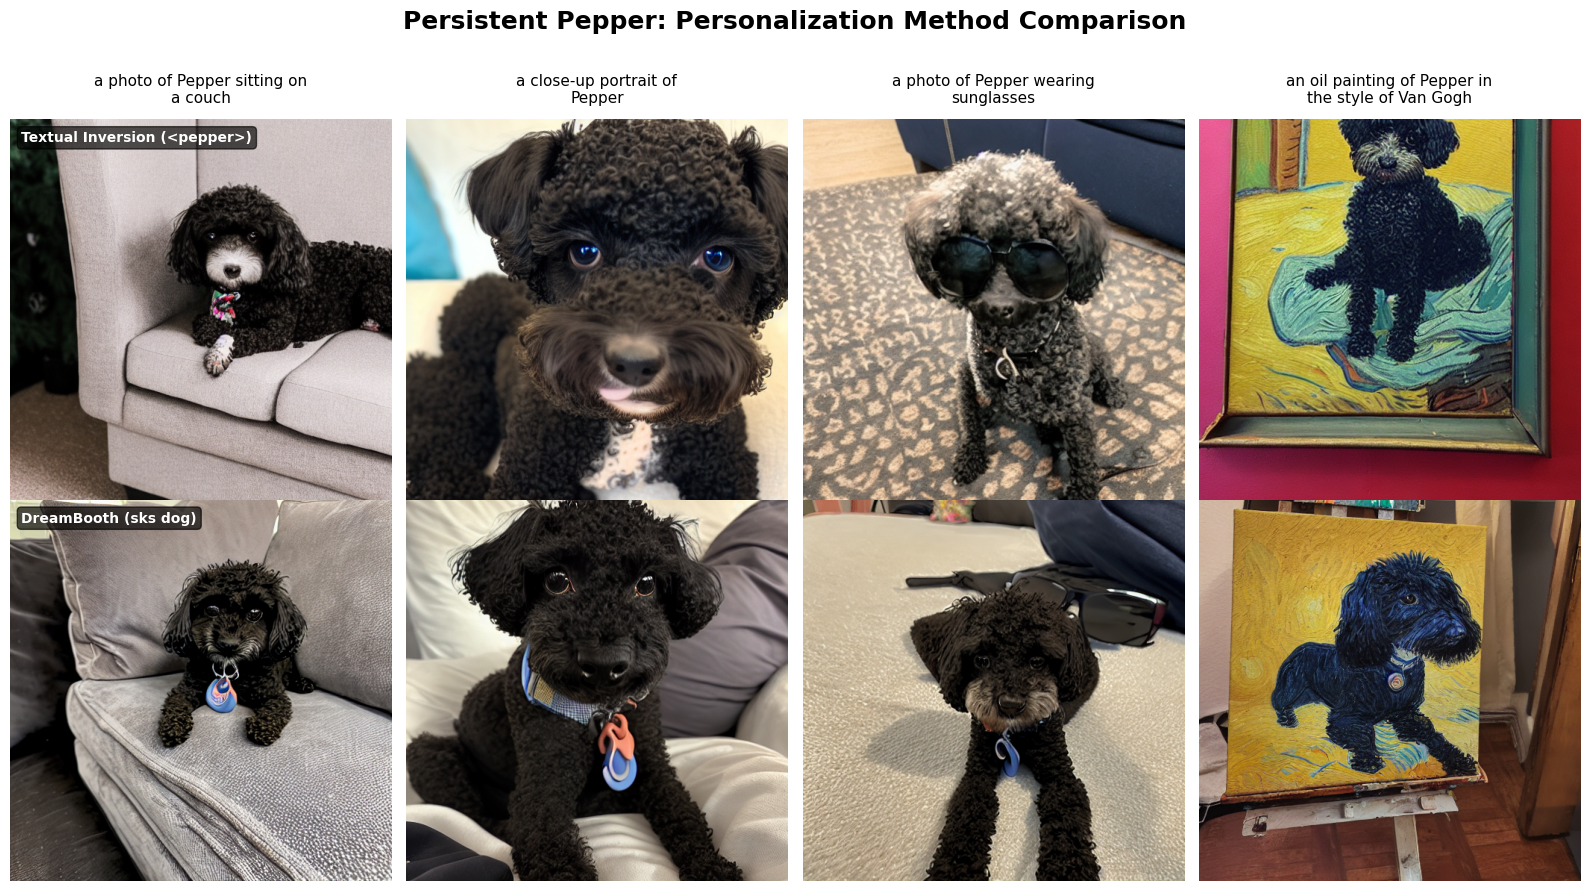

Saved presentation figure to: /content/gdrive/MyDrive/persistent-pepper/cache/checkpoints/persistent_pepper_method_comparison.png

Textual Inversion (<pepper>)
CLIP-I (identity, gen vs refs):   0.7410
CLIP-T (prompt alignment):        0.2730
# generated images considered:    4
# reference images considered:    24

DreamBooth (sks dog)
CLIP-I (identity, gen vs refs):   0.8107
CLIP-T (prompt alignment):        0.2357
# generated images considered:    4
# reference images considered:    24


In [ ]:
import textwrap

import matplotlib.pyplot as plt
from PIL import Image

METHOD_DISPLAY_NAMES = {
    'textual_inversion': 'Textual Inversion (<pepper>)',
    'dreambooth': 'DreamBooth (sks dog)',
}

number_of_methods = len(EVALUATION_RUNS)
number_of_prompts = len(PRESENTATION_PROMPTS)
figure, axes_grid = plt.subplots(
    number_of_methods,
    number_of_prompts,
    figsize=(4.0 * number_of_prompts, 4.4 * number_of_methods),
    squeeze=False,
)

for row_index, (method_name, evaluation_settings) in enumerate(EVALUATION_RUNS.items()):
    generated_image_paths = sorted(evaluation_settings['output_directory'].glob('gen_*.png'))
    if len(generated_image_paths) < number_of_prompts:
        raise FileNotFoundError(
            f"Expected at least {number_of_prompts} generated images for {method_name}, "
            f"but found {len(generated_image_paths)} in {evaluation_settings['output_directory']}. "
            'Rerun Step 9 after retraining with the latest code.'
        )

    for column_index, generated_image_path in enumerate(generated_image_paths[:number_of_prompts]):
        axis = axes_grid[row_index][column_index]
        axis.imshow(Image.open(generated_image_path).convert('RGB'))
        axis.axis('off')

        if row_index == 0:
            prompt_title = PRESENTATION_PROMPTS[column_index].replace('{subject}', 'Pepper')
            axis.set_title(
                textwrap.fill(prompt_title, width=28),
                fontsize=11,
                pad=12,
            )

        if column_index == 0:
            axis.text(
                0.03, 0.97,
                METHOD_DISPLAY_NAMES[method_name],
                transform=axis.transAxes,
                fontsize=10,
                weight='bold',
                va='top',
                ha='left',
                color='white',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='black', alpha=0.65),
            )

figure.suptitle(
    'Persistent Pepper: Personalization Method Comparison',
    fontsize=18,
    weight='bold',
    y=1.02,
)
figure.tight_layout()

presentation_figure_path = DRIVE_CHECKPOINTS_ROOT / 'persistent_pepper_method_comparison.png'
figure.savefig(
    presentation_figure_path,
    dpi=200,
    bbox_inches='tight',
)
plt.show()
print('Saved presentation figure to:', presentation_figure_path)

for method_name, evaluation_settings in EVALUATION_RUNS.items():
    clip_report_path = evaluation_settings['output_directory'] / 'clip_report.txt'
    print('\n' + '=' * 80)
    print(METHOD_DISPLAY_NAMES[method_name])
    if clip_report_path.is_file():
        print(clip_report_path.read_text())
    else:
        print('No CLIP report found yet.')

# Training progress previews

If `preview_every_n_steps` was enabled during training, this renders the saved
preview images as a timeline for each method. This is useful for showing how the
personalization emerges over time and for assessing how training is doing.

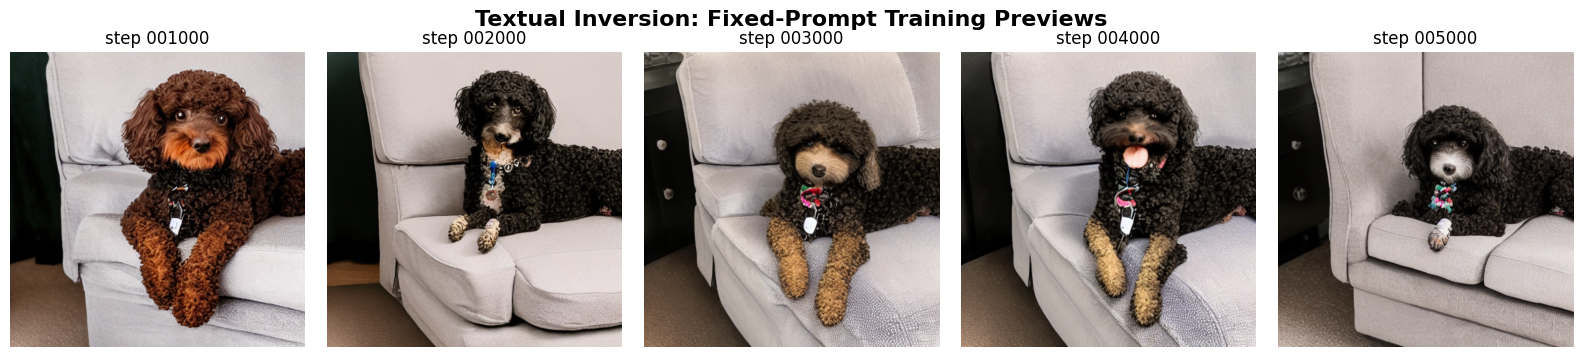

Saved preview timeline to: /content/gdrive/MyDrive/persistent-pepper/cache/checkpoints/textual_inversion_preview_timeline.png


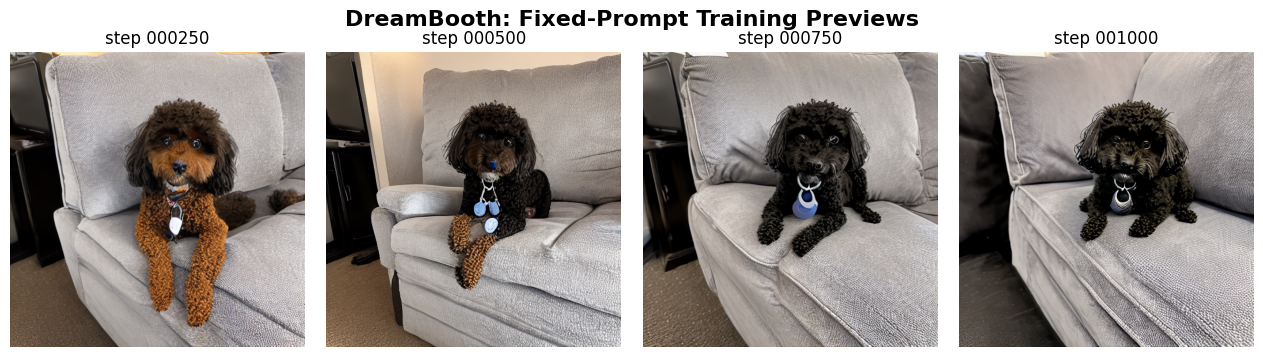

Saved preview timeline to: /content/gdrive/MyDrive/persistent-pepper/cache/checkpoints/dreambooth_preview_timeline.png


In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

PREVIEW_DIRECTORIES = {
    'Textual Inversion': TEXTUAL_INVERSION_OUTPUT_DIRECTORY / 'previews',
    'DreamBooth': DREAMBOOTH_OUTPUT_DIRECTORY / 'previews',
}

for method_display_name, preview_directory in PREVIEW_DIRECTORIES.items():
    preview_image_paths = sorted(preview_directory.glob('preview_step_*.png'))
    if not preview_image_paths:
        print(f'No preview images found for {method_display_name} at {preview_directory}')
        continue

    figure, axes_grid = plt.subplots(
        1,
        len(preview_image_paths),
        figsize=(3.2 * len(preview_image_paths), 3.6),
        squeeze=False,
    )
    for axis, preview_image_path in zip(axes_grid[0], preview_image_paths):
        axis.imshow(Image.open(preview_image_path).convert('RGB'))
        axis.set_title(preview_image_path.stem.replace('preview_', '').replace('_', ' '))
        axis.axis('off')

    figure.suptitle(
        f'{method_display_name}: Fixed-Prompt Training Previews',
        fontsize=16,
        weight='bold',
    )
    figure.tight_layout()
    preview_timeline_path = (
        DRIVE_CHECKPOINTS_ROOT
        / f"{method_display_name.lower().replace(' ', '_')}_preview_timeline.png"
    )
    figure.savefig(
        preview_timeline_path,
        dpi=200,
        bbox_inches='tight',
    )
    plt.show()
    print('Saved preview timeline to:', preview_timeline_path)

Textual Inversion inference examples

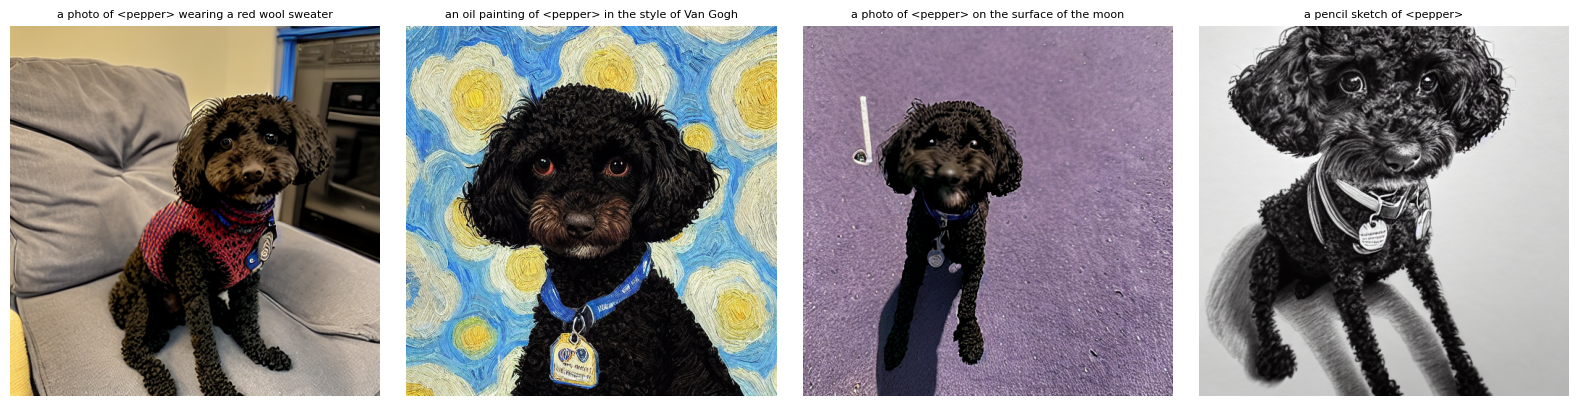

In [ ]:
prompt_templates = [
    'a photo of {subject} wearing a red wool sweater',
    'an oil painting of {subject} in the style of Van Gogh',
    'a photo of {subject} on the surface of the moon',
    'a pencil sketch of {subject}',
]
fully_substituted_prompts = [
    prompt_template.format(subject=subject_phrase_for_prompts)
    for prompt_template in prompt_templates
]

sampling_configuration = SamplingConfiguration(
    number_of_inference_steps=50,
    classifier_free_guidance_scale=7.5,
    random_seed=42,
)

generated_pil_images = sample_images_from_prompts(
    stable_diffusion_components=stable_diffusion_components,
    prompt_texts=fully_substituted_prompts,
    sampling_configuration=sampling_configuration,
)

figure, axes_grid = plt.subplots(
    1,
    len(generated_pil_images),
    figsize=(4 * len(generated_pil_images), 4),
)
if len(generated_pil_images) == 1:
    axes_grid = [axes_grid]
for axis, generated_pil_image, fully_substituted_prompt in zip(
    axes_grid,
    generated_pil_images,
    fully_substituted_prompts,
):
    axis.imshow(generated_pil_image)
    axis.set_title(fully_substituted_prompt, fontsize=8)
    axis.axis('off')
plt.tight_layout()
plt.show()

Dreambooth inference examples

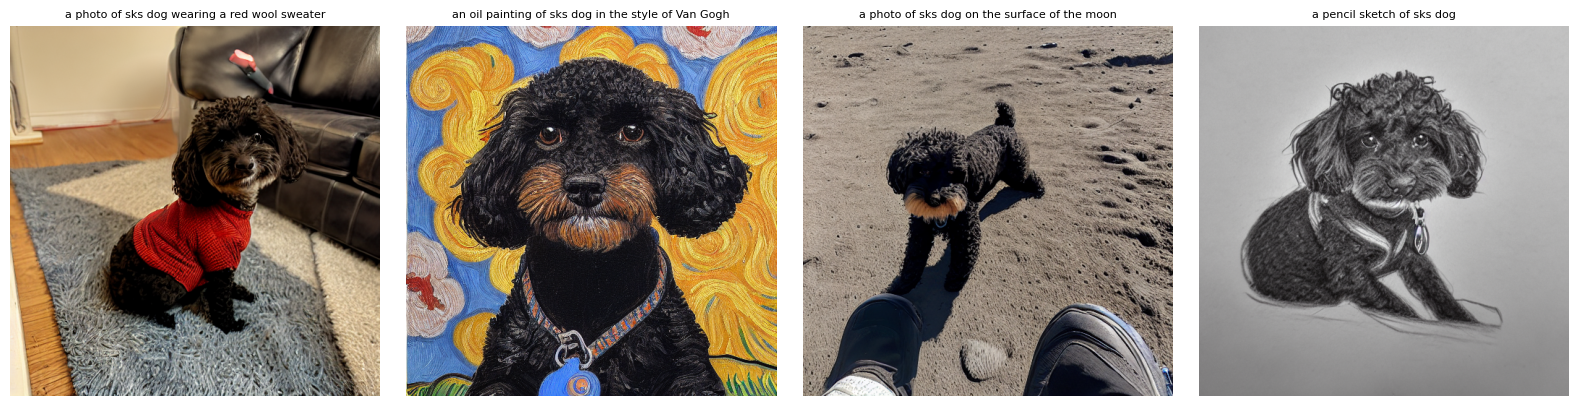

In [ ]:
prompt_templates = [
    'a photo of {subject} wearing a red wool sweater',
    'an oil painting of {subject} in the style of Van Gogh',
    'a photo of {subject} on the surface of the moon',
    'a pencil sketch of {subject}',
]
fully_substituted_prompts = [
    prompt_template.format(subject=subject_phrase_for_prompts)
    for prompt_template in prompt_templates
]

sampling_configuration = SamplingConfiguration(
    number_of_inference_steps=50,
    classifier_free_guidance_scale=7.5,
    random_seed=42,
)

generated_pil_images = sample_images_from_prompts(
    stable_diffusion_components=stable_diffusion_components,
    prompt_texts=fully_substituted_prompts,
    sampling_configuration=sampling_configuration,
)

figure, axes_grid = plt.subplots(
    1,
    len(generated_pil_images),
    figsize=(4 * len(generated_pil_images), 4),
)
if len(generated_pil_images) == 1:
    axes_grid = [axes_grid]
for axis, generated_pil_image, fully_substituted_prompt in zip(
    axes_grid,
    generated_pil_images,
    fully_substituted_prompts,
):
    axis.imshow(generated_pil_image)
    axis.set_title(fully_substituted_prompt, fontsize=8)
    axis.axis('off')
plt.tight_layout()
plt.show()